In [1]:
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
load_dotenv()

model = ChatOpenAI(model="gpt-5.6-luna")
response = model.invoke("안녕하세요!")
print(response.content)

안녕하세요! 무엇을 도와드릴까요?


### 상태 정의하기

In [2]:
from typing import Annotated # annotated는 타입 힌트를 사용할 때 사용하는 함수
from typing_extensions import TypedDict # TypedDict는 딕셔너리 타입을 정의할 때 사용하는 함수

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

class State(TypedDict):	#①
    """
    State 클래스는 TypedDict를 상속받습니다.

    속성:
        messages (Annotated[list[str], add_messages]): 메시지들은 "list" 타입을 가집니다.   #②
       'add_messages' 함수는 이 상태 키가 어떻게 업데이트되어야 하는지를 정의합니다.  #③
        (이 경우, 메시지를 덮어쓰는 대신 리스트에 추가합니다)
    """
    messages: Annotated[list[str], add_messages]	#②

# StateGraph 클래스를 사용하여 State 타입의 그래프를 생성합니다.
graph_builder = StateGraph(State) #④

### 노드 생성하기

In [3]:
def generate(state: State):	#①
    """
    주어진 상태를 기반으로 챗봇의 응답 메시지를 생성합니다.

    매개변수:
    state (State): 현재 대화 상태를 나타내는 객체로, 이전 메시지들이 포함되어 있습니다.
		
    반환값:
    dict: 모델이 생성한 응답 메시지를 포함하는 딕셔너리. 
          형식은 {"messages": [응답 메시지]}입니다.
    """ 
    return {"messages": [model.invoke(state["messages"])]}	#②

graph_builder.add_node("generate", generate)	#③

### 엣지 설정하기
- graph 선언

In [4]:
graph_builder.add_edge(START, "generate")
graph_builder.add_edge("generate", END)    

graph = graph_builder.compile()

- 그래프 도식화 하기

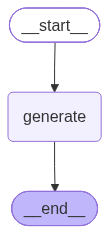

In [5]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception: 
    pass

- 리스트에 문장 추가하기

In [6]:
response = graph.invoke({"messages": ["안녕하세요! 저는 이성용입니다"]})

print(type(response))
response

<class 'dict'>


{'messages': [HumanMessage(content='안녕하세요! 저는 이성용입니다', additional_kwargs={}, response_metadata={}, id='0035e2a6-4fa1-429f-91e2-02843efb71f0'),
  AIMessage(content='안녕하세요, 이성용님! 만나서 반갑습니다. 무엇을 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 25, 'prompt_tokens': 14, 'total_tokens': 39, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-EXkTvwtRouZ2FTRr6HQk1VXgoEYM3', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a12a5e-9ead-7451-84ec-c7a341a7f29d-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 14, 'output_tokens': 25, 'total_token

- 이전 대화 내용에 새 메시지 추가하기

In [7]:
response["messages"].append("제 이름을 아시나요?")
graph.invoke(response)

{'messages': [HumanMessage(content='안녕하세요! 저는 이성용입니다', additional_kwargs={}, response_metadata={}, id='0035e2a6-4fa1-429f-91e2-02843efb71f0'),
  AIMessage(content='안녕하세요, 이성용님! 만나서 반갑습니다. 무엇을 도와드릴까요?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 25, 'prompt_tokens': 14, 'total_tokens': 39, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5.6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-EXkTvwtRouZ2FTRr6HQk1VXgoEYM3', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a12a5e-9ead-7451-84ec-c7a341a7f29d-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 14, 'output_tokens': 25, 'total_token

### 스트림 출력하기

In [8]:
inputs = {"messages": [("human", "한국과 일본의 관계에 대해 자세히 알려줘")]}
for chunk, _ in graph.stream(inputs, stream_mode="messages"):
    print(chunk.content, end="")

한국과 일본의 관계는 **지리적으로 가깝고 경제·안보·문화적으로 긴밀하지만, 역사 인식과 영토 문제 때문에 반복적으로 갈등하는 관계**입니다. 흔히 “가깝고도 먼 이웃”이라고 표현됩니다. 여기서는 주로 대한민국과 일본의 관계를 설명하겠습니다.

---

## 1. 관계의 기본 성격

한일 관계에는 다음과 같은 특징이 함께 존재합니다.

- **지리적 인접성**: 부산과 일본 규슈는 매우 가까워 인적·물적 교류가 활발합니다.
- **경제적 상호의존**: 제조업, 부품·소재, 기술, 관광, 투자 등에서 서로 중요한 파트너입니다.
- **안보 협력의 필요성**: 북한의 핵·미사일 문제, 중국의 부상, 동아시아 해양안보 때문에 협력이 필요합니다.
- **역사 문제의 지속**: 일본의 식민지 지배, 강제동원, 일본군 ‘위안부’, 역사 교과서 문제 등이 양국 관계를 어렵게 합니다.
- **대중문화 교류**: 한류와 일본 대중문화가 서로 큰 영향을 주고받고 있습니다.
- **국내정치의 영향**: 양국 모두 선거와 여론에 따라 대일·대한 정책이 크게 흔들릴 수 있습니다.

즉, 한일 관계는 단순한 우호 또는 적대 관계가 아니라, **협력과 갈등이 동시에 진행되는 복합적 관계**입니다.

---

# 2. 역사적 배경

## 2.1 고대와 중세

고대부터 한반도와 일본 열도 사이에는 사람, 기술, 종교, 문화의 교류가 있었습니다.

- 한반도를 통해 일본에 불교와 유교, 한자 문화가 전해졌습니다.
- 백제·신라·고구려 등과 일본의 야마토 정권 사이에 외교와 교류가 있었습니다.
- 도자기, 금속 기술, 건축, 문학, 행정제도 등 여러 분야에서 한반도의 영향이 일본에 전달되었습니다.
- 반대로 일본과의 해상 교류를 통해 물자와 문화도 오갔습니다.

중세에는 왜구 문제와 임진왜란 등이 발생했지만, 조선과 일본 사이에 사절단 교류도 있었습니다. 특히 조선통신사는 에도 시대 일본과 조선의 공식 외교 채널 역할을 했습니다.

## 2.2 임진왜란

1592년과 1597년 일본이 조선을 

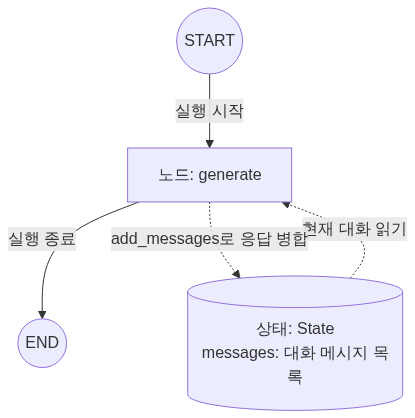

In [9]:
from IPython.display import Image, display
from langchain_core.runnables.graph_mermaid import draw_mermaid_png

mermaid_code = """
flowchart TD
    START((START)) -->|"실행 시작"| GENERATE["노드: generate"]
    GENERATE -->|"실행 종료"| END((END))

    STATE[("상태: State<br/>messages: 대화 메시지 목록")]
    STATE -.->|"현재 대화 읽기"| GENERATE
    GENERATE -.->|"add_messages로 응답 병합"| STATE
"""

display(Image(data=draw_mermaid_png(mermaid_code)))

- 실선: 노드의 실행 순서인 엣지
- 점선: 상태를 읽고 갱신하는 관계를 설명하는 표시

### LangGraph 챗봇의 기본 구성

- **상태(State) 정의**: 노드들이 공유할 데이터를 정의한다. 이 예제는 `messages`에 대화 내용을 저장하고, `add_messages`로 새 메시지를 기존 대화에 합친다.
- **노드(Node) 생성**: 상태를 받아 작업을 수행하고, 상태에 반영할 결과를 반환한다. `generate` 노드는 대화 내용을 모델에 전달하고 응답 메시지를 반환한다.
- **엣지(Edge) 설정**: 노드의 실행 순서를 연결한다. `START → generate → END`로 응답을 한 번 생성한 뒤 종료한다.

`compile()`로 실행 가능한 그래프를 만들고, `invoke()`로 입력 상태를 전달해 실행한다.